In [1]:
# Imports
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
%matplotlib inline
import sklearn
import pandas as pd
from scipy import signal
import seaborn as sns

import netCDF4 as nc
from netCDF4 import Dataset
import xarray as xr

import tigramite
from tigramite import data_processing as pp
from tigramite.toymodels import structural_causal_processes as toys
from tigramite import plotting as tp
from tigramite.pcmci import PCMCI
from tigramite.lpcmci import LPCMCI

from tigramite.independence_tests.parcorr import ParCorr
from tigramite.independence_tests.robust_parcorr import RobustParCorr
from tigramite.independence_tests.gpdc import GPDC
from tigramite.independence_tests.cmiknn import CMIknn

from tigramite.models import LinearMediation, Prediction

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
path = '/Users/ernest/Research/thesis/_paper_/'

## master dataframe

In [3]:
df = pd.read_csv(path + 'data/ERA5_1940-2022.csv', index_col=[0])

# causal discovery

In [14]:
def getgraph(test, data_mask, alpha_level_v, tau_min, tau_max, i, j, tau, k):

    CE = []
    
    data = np.array(test)

    T, N = data.shape

    names = index_selection
    dataframe = pp.DataFrame(data, 
                         mask=data_mask,
                         datatime = {0:np.arange(len(data))}, 
                         var_names=names)

    pcmci = PCMCI(
    dataframe=dataframe, 
    cond_ind_test=ParCorr(mask_type='y'),
    verbosity=0)
    results = pcmci.run_pcmciplus(tau_min=tau_min, tau_max=tau_max, 
                                  pc_alpha=alpha_level_v, fdr_method=None,
                                  reset_lagged_links=True)

    q_matrix = pcmci.get_corrected_pvalues(p_matrix=results['p_matrix'], tau_max=tau_max, 
                                       fdr_method='fdr_bh', exclude_contemporaneous=False)

    graph = pcmci.get_graph_from_pmatrix(p_matrix=q_matrix, alpha_level=alpha_level_v, 
            tau_min=tau_min, tau_max=tau_max, link_assumptions=None)

    all_parents = pcmci.return_parents_dict(graph, val_matrix=results['val_matrix'], 
                                                      include_lagzero_parents=False)

    med = LinearMediation(dataframe=dataframe,
            mask_type = 'y')
    med.fit_model(all_parents = all_parents, tau_max=tau_max) 
    
    Links = med.get_val_matrix()
    
    # small causal graphs from CD
    '''
    tp.plot_graph(figsize=(2,4),
    val_matrix=Links,
    graph=graph,
    node_label_size=20,
    link_label_fontsize=18,
    curved_radius=-0.1,
    vmax_nodes=0.9,
    vmin_nodes=-0.9,
    vmax_edges=0.9,
    vmin_edges=-0.9,
    var_names=names,
    show_colorbar=False,
    )
    plt.savefig(f'/Users/ernest/Research/thesis/_paper_/figures/cstat/aa{k}_graph_{alpha_level_v}.png', 
           dpi=300, bbox_inches='tight', transparent=True)
    '''
    CE.append(med.get_ce(i=i, tau=tau, j=j))
    return(CE)

In [15]:
mask_key = 'Southern AR dry season'
mask = df[[f'{mask_key}', f'{mask_key}', f'{mask_key}']]
data_mask = np.array(mask)

test = df[['AMOC_era5', 'CLLJ', 'SAR_prec']]
index_selection = ['AMOC', 'CLLJ', 'SAR_prec']

In [16]:
# evaluate data every x years:
stepsize = 1*12

# keep window in multiples of 12, to cover full years
n = 40
window = n*12
alpha_level_v = 0.05

indices = (np.arange(0,len(df)-window,stepsize)/12).astype(int)

CE_AMOCPREC = []
CE_AMOCPREC2 = []
CE_AMOCCLLJ = []
CE_CLLJPREC = []

for k in np.arange(0,len(df)-window,stepsize):
    test = df[['AMOC_era5', 'CLLJ', 'SAR_prec']][k:k+window]
    index_selection = ['AMOC', 'CLLJ', 'PREC']
    mask=data_mask[k:k+window]
    CE_AMOCPREC.append(getgraph(test, mask, alpha_level_v, 0, 5, 0, 2, -3, k))
    CE_AMOCPREC2.append(getgraph(test, mask, alpha_level_v, 0, 5, 0, 2, -2, k))
    CE_AMOCCLLJ.append(getgraph(test, mask, alpha_level_v, 0, 5, 0, 1, -2, k))
    CE_CLLJPREC.append(getgraph(test, mask, alpha_level_v, 0, 5, 1, 2, -1, k))

## with prescribed parents / links

In [17]:
all_parents = {0: [(0, -1)], 1: [(1, -1), (1, -2), (0, -2)], 2: [(1, -1), (0, -2)]}

In [18]:
def getgraph_fixed(df, indices, index_selection, all_parents, tau_min, tau_max):

    CE = []
    df = df
    
    test = df[indices]
    index_selection = index_selection
    
    data = np.array(test)
    
    mask_key = 'Southern AR dry season'
    mask = df[[f'{mask_key}', f'{mask_key}', f'{mask_key}']]
    data_mask = np.array(mask)
    
    T, N = data.shape
    # Initialize dataframe object, specify time axis and variable names
    names = index_selection
    dataframe = pp.DataFrame(data, 
                         mask=data_mask,
                         datatime = {0:np.arange(len(data))}, 
                         var_names=names)

    med = LinearMediation(dataframe=dataframe,
            mask_type = 'y')
    med.fit_model(all_parents = all_parents, tau_max=tau_max) 
    Links = med.get_val_matrix()
    return med

In [19]:
def cee(n, df, variables, index_selection):
    stepsize = 1*12
    n = n
    window = n*12
    indices = (np.arange(0,len(df)-window,stepsize)/12).astype(int)

    AMOC_CLLJ = []
    CLLJ_PREC = []
    AMOC_PREC = []
    AMOC_PREC2= []

    for k in np.arange(0,len(df)-window,stepsize):
        med = getgraph_fixed(df[k:k+window], variables, index_selection, all_parents, 0, 5)
        AMOC_CLLJ.append(med.get_ce(i=0, tau=-2, j=1))
        CLLJ_PREC.append(med.get_ce(i=1, tau=-1, j=2))
        AMOC_PREC.append(med.get_ce(i=0, tau=-3, j=2))
        AMOC_PREC2.append(med.get_ce(i=0, tau=-2, j=2))


    return indices, AMOC_CLLJ, CLLJ_PREC, AMOC_PREC, AMOC_PREC2

In [20]:
n = 40
variables = ['AMOC_era5', 'CLLJ', 'SAR_prec']
index_selection= ['AMOC', 'CLLJ', 'PREC']

indices, AMOC_CLLJ, CLLJ_PREC, AMOC_PREC, AMOC_PREC2 = cee(n, df, variables, index_selection);

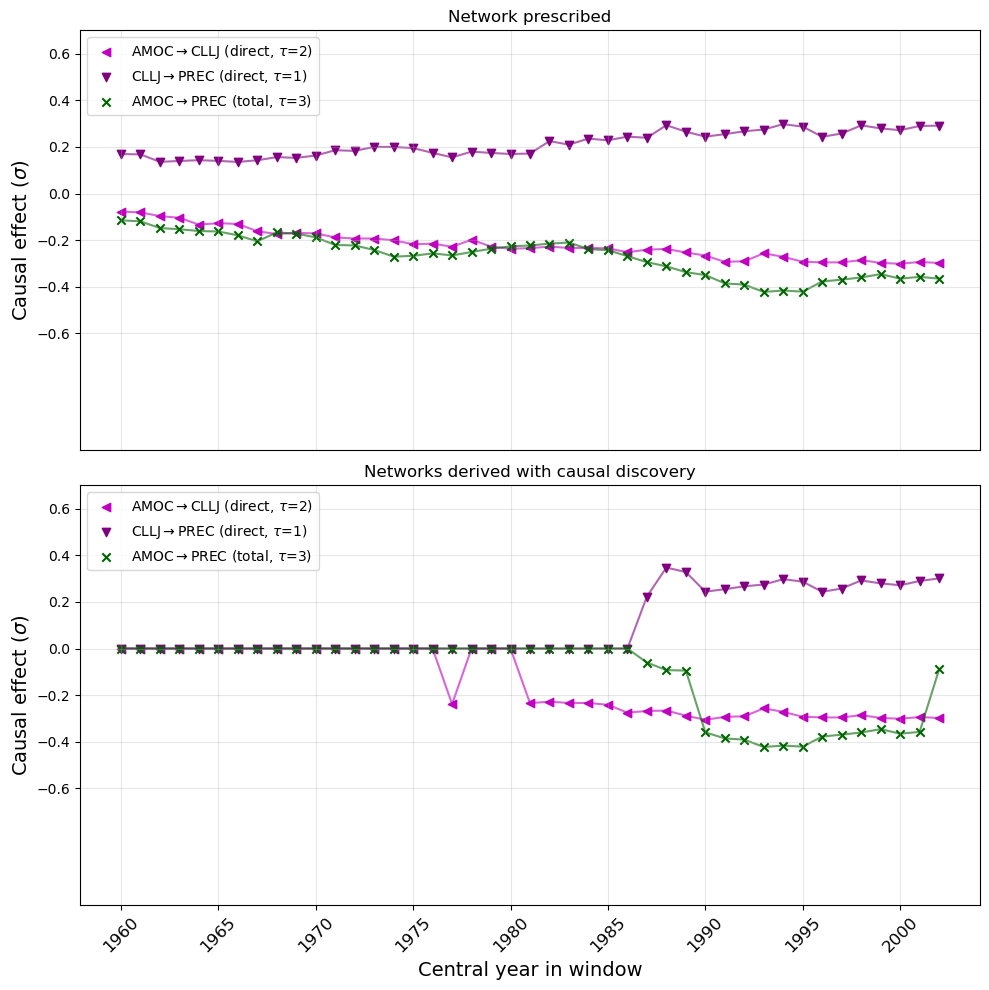

In [27]:
years_array = np.array([date.split('-')[0] for date in df.time[0::12]])[indices]
xlabels = years_array.astype(int) + int(n/2)

# Create the figure and two side-by-side subplots
fig, (ax2, ax1) = plt.subplots(2, 1, figsize=(10, 10))  # Share y-axis for consistent comparison

# Plot data on the first panel (ax1)
ax1.plot(xlabels, CE_AMOCCLLJ, color='m', zorder=1, alpha=.6)
ax1.scatter(xlabels, CE_AMOCCLLJ, label=r"AMOC$\rightarrow$CLLJ (direct, $\tau$=2)", color='m', marker="<", zorder=1)
ax1.plot(xlabels, CE_CLLJPREC, color='purple', zorder=1, alpha=.6)
ax1.scatter(xlabels, CE_CLLJPREC, label=r"CLLJ$\rightarrow$PREC (direct, $\tau$=1)", color='purple', marker="v", zorder=1)
#ax1.plot(xlabels, CE_AMOCPREC2, color='lime', zorder=1, alpha=.4)
#ax1.scatter(xlabels, CE_AMOCPREC2, label=r"AMOC$\rightarrow$PREC (direct, $\tau$=2)", color='lime', marker="x", zorder=1, alpha=.6)
ax1.plot(xlabels, CE_AMOCPREC, color='darkgreen', zorder=1, alpha=.6)
ax1.scatter(xlabels, CE_AMOCPREC, label=r"AMOC$\rightarrow$PREC (total, $\tau$=3)", color='darkgreen', marker="x", zorder=1)

# Plot data on the second panel (ax2)
ax2.plot(xlabels, AMOC_CLLJ, color='m', zorder=1, alpha=.6)
ax2.scatter(xlabels, AMOC_CLLJ, label=r"AMOC$\rightarrow$CLLJ (direct, $\tau$=2)", color='m', marker="<", zorder=1)
ax2.plot(xlabels, CLLJ_PREC, color='purple', zorder=1, alpha=.6)
ax2.scatter(xlabels, CLLJ_PREC, label=r"CLLJ$\rightarrow$PREC (direct, $\tau$=1)", color='purple', marker="v", zorder=1)
#ax2.plot(xlabels, AMOC_PREC2, color='lime', zorder=1, alpha=.4)
#ax2.scatter(xlabels, AMOC_PREC2, label=r"AMOC$\rightarrow$PREC (direct, $\tau$=2)", color='lime', marker="x", zorder=1, alpha=.6)
ax2.plot(xlabels, AMOC_PREC, color='darkgreen', zorder=1, alpha=.6)
ax2.scatter(xlabels, AMOC_PREC, label=r"AMOC$\rightarrow$PREC (total, $\tau$=3)", color='darkgreen', marker="x", zorder=1)

# Common properties for both panels
for ax in (ax1, ax2):
    ax.set_yticks(np.arange(-0.6, 1, 0.2))
    ax.set_ylim(-1.1, 0.7)
  #  ax.axhline(y=0, color='lightgrey', alpha=.5)
    ax.tick_params(left=True, bottom=True)

ax1.set_title('Networks derived with causal discovery')
ax2.tick_params(labelbottom=False, bottom=False)
ax2.set_xticks(xlabels[::5])

ax2.set_title('Network prescribed')
ax1.set_xticks(xlabels[::5])
ax1.set_xticklabels(xlabels[::5], rotation=45, fontsize=12)
ax1.set_xlabel('Central year in window', fontsize=14)

# Y-axis label for the leftmost panel
ax1.set_ylabel(r'Causal effect ($\sigma$)', fontsize=14)
ax2.set_ylabel(r'Causal effect ($\sigma$)', fontsize=14)

# Add legends
ax1.legend(fontsize=10, loc=2)
ax2.legend(fontsize=10, loc=2)

ax1.grid(alpha=.3)
ax2.grid(alpha=.3)

# Adjust layout and display
plt.tight_layout()

plt.savefig(path + 'figures/Figure_5-causalstat.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()